# EDA: vì sao chia train/val/test theo nhóm

Ba model trong `youonlycodeonce/` đều train và chấm điểm trên cùng một cách chia, lưu ở `youonlycodeonce/splits/`. Cách chia này không xáo ngẫu nhiên từng ảnh như thường làm. Các ảnh gần giống nhau được gom thành nhóm, rồi cả nhóm được đưa vào cùng một tập.

Notebook này giải thích vì sao lại chia như vậy:
1. bộ dữ liệu có rất nhiều ảnh gần giống nhau;
2. chia ngẫu nhiên thì khoảng 1/4 ảnh test có "bản sao" nằm trong train;
3. model đoán gần như đúng hết những ảnh đó, nên accuracy bị thổi phồng. Mức thổi phồng lại khác nhau giữa các model, nên so sánh model trên cách chia ngẫu nhiên kém tin cậy.

Notebook chỉ cần thư mục `data/` (tải theo README) và các file trong `youonlycodeonce/`. Chạy từ thư mục `notebooks/` hay từ gốc repo đều được.

In [1]:
import collections
import csv
import hashlib
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

plt.rcParams["figure.dpi"] = 80

# thư mục gốc của repo (chạy từ notebooks/ hoặc từ gốc repo)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
SPLITS = ROOT / "youonlycodeonce"

with open(SPLITS / "splits" / "groups.csv") as f:
    rows = list(csv.DictReader(f))  # mỗi dòng: image, group, split
group_of = {r["image"]: r["group"] for r in rows}
split_of = {r["image"]: r["split"] for r in rows}
images = sorted(group_of)
class_of = {im: im.split("/")[0] for im in images}
classes = sorted(set(class_of.values()))
group_members = collections.defaultdict(list)
for im in images:
    group_members[group_of[im]].append(im)
print(len(images), "ảnh,", len(classes), "lớp,", len(group_members), "nhóm")

4947 ảnh, 25 lớp, 3974 nhóm


In [2]:
def show(names, ncols=8, size=1.6, titles=None):
    """Hiện một dãy ảnh thành lưới, tiêu đề mặc định là tên file."""
    nrows = (len(names) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, name, title in zip(axes.flat, names, titles or [n.split("/")[1] for n in names]):
        ax.imshow(Image.open(DATA / name).convert("RGB").resize((128, 128)))
        ax.set_title(title, fontsize=7)
    plt.tight_layout()
    plt.show()

## 1. Tổng quan

Bộ Freiburg Groceries có 4.947 ảnh, chia thành 25 lớp. Ảnh được chụp bằng 4 chiếc điện thoại, phần lớn ở các cửa hàng tại Freiburg (Đức), một số ở nhà và văn phòng. Mỗi ảnh được thu nhỏ cho vừa khung 256×256 rồi tô xám phần còn trống, nên nhiều ảnh có dải xám ở trên-dưới hoặc hai bên.

Số ảnh mỗi lớp chênh nhau khá nhiều, vì vậy cả hai cách chia đều chia riêng trong từng lớp theo tỉ lệ 70/15/15.

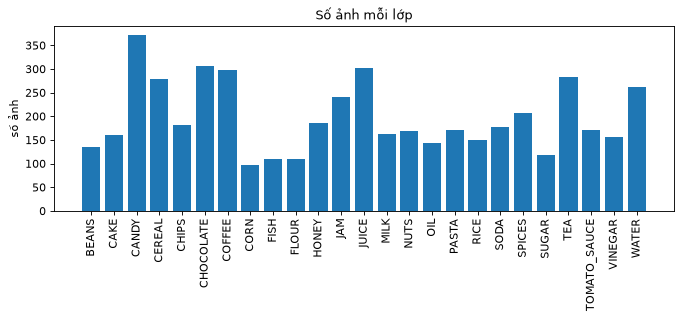

kích thước ảnh: {(256, 256): 4947}
lớp ít ảnh nhất: ('CORN', 97) | nhiều nhất: ('CANDY', 372)


In [3]:
count = collections.Counter(class_of.values())
plt.figure(figsize=(10, 3))
plt.bar(classes, [count[c] for c in classes])
plt.xticks(rotation=90)
plt.ylabel("số ảnh")
plt.title("Số ảnh mỗi lớp")
plt.show()

print("kích thước ảnh:", dict(collections.Counter(Image.open(DATA / im).size for im in images)))
print("lớp ít ảnh nhất:", min(count.items(), key=lambda x: x[1]), "| nhiều nhất:", max(count.items(), key=lambda x: x[1]))

## 2. Có rất nhiều ảnh gần giống nhau

Người chụp thường chụp một kệ hàng vài lần liền, chỉ đổi góc hoặc khoảng cách một chút. Vì vậy nhiều ảnh gần như giống hệt nhau, và các ảnh này thường có số thứ tự file liền nhau. Mỗi hàng dưới đây là một nhóm như vậy:

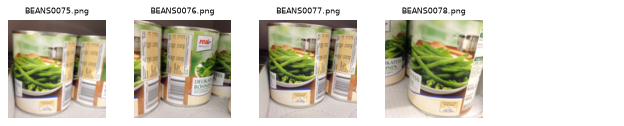

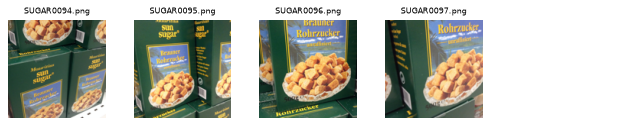

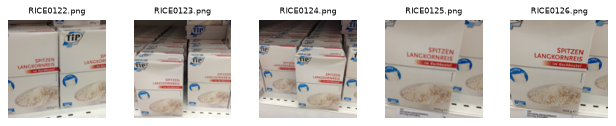

In [4]:
for im in ["BEANS/BEANS0075.png", "SUGAR/SUGAR0094.png", "RICE/RICE0122.png"]:
    show(group_members[group_of[im]], ncols=5)

Có cả những ảnh trùng nhau từng pixel, tức là cùng một bức ảnh bị lưu hai lần dưới hai tên khác nhau:

14 cặp ảnh trùng nhau từng pixel:
   COFFEE/COFFEE0092.png = COFFEE/COFFEE0193.png
   COFFEE/COFFEE0111.png = COFFEE/COFFEE0192.png
   COFFEE/COFFEE0129.png = COFFEE/COFFEE0189.png
   COFFEE/COFFEE0187.png = COFFEE/COFFEE0191.png
   COFFEE/COFFEE0188.png = COFFEE/COFFEE0190.png
   SPICES/SPICES0001.png = SPICES/SPICES0181.png
   SPICES/SPICES0007.png = SPICES/SPICES0169.png
   SPICES/SPICES0052.png = SPICES/SPICES0175.png
   SPICES/SPICES0063.png = SPICES/SPICES0179.png
   SPICES/SPICES0074.png = SPICES/SPICES0180.png
   SPICES/SPICES0099.png = SPICES/SPICES0182.png
   SPICES/SPICES0124.png = SPICES/SPICES0177.png
   SPICES/SPICES0151.png = SPICES/SPICES0176.png
   SPICES/SPICES0153.png = SPICES/SPICES0178.png


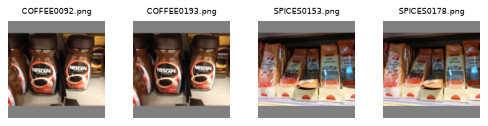

In [5]:
by_hash = collections.defaultdict(list)
for im in images:
    pixels = np.asarray(Image.open(DATA / im).convert("RGB"))
    by_hash[hashlib.md5(pixels.tobytes()).hexdigest()].append(im)
duplicates = [v for v in by_hash.values() if len(v) > 1]
print(len(duplicates), "cặp ảnh trùng nhau từng pixel:")
for d in duplicates:
    print("  ", " = ".join(d))
show(duplicates[0] + duplicates[-1], ncols=4)

## 3. Cách gom nhóm

`youonlycodeonce/make_splits.py` so từng cặp ảnh cùng lớp:
- Thuật toán ORB tìm các điểm đặc trưng trong mỗi ảnh (góc chữ, mép logo, hoa văn trên bao bì), rồi ghép mỗi điểm với điểm trông giống nó nhất ở ảnh kia.
- RANSAC chỉ giữ lại những cặp điểm khớp cùng một phép dịch, xoay, phóng to hoặc thu nhỏ, tức là các điểm nằm đúng vị trí tương đối như nhau ở cả hai ảnh.
- Số cặp được giữ lại gọi là số điểm khớp: hai ảnh chụp cùng một vật thì có nhiều điểm khớp.

Ảnh được gom nhóm theo 3 luật:
1. ảnh trùng nhau từng pixel thì cùng nhóm;
2. hai ảnh có ít nhất 10 điểm khớp thì cùng nhóm. Thử trên 40.000 cặp ảnh khác lớp, không cặp nào khớp quá 5 điểm, nên ngưỡng 10 điểm gần như không nối nhầm;
3. hai ảnh khớp ít nhất 6 điểm và có số thứ tự file cách nhau không quá 3 (chụp liên tiếp) thì cùng nhóm.

Luật 2 không chỉ nối các ảnh chụp cùng một cảnh. Nó còn nối các ảnh có cùng mẫu bao bì (cùng logo, cùng hãng) dù chụp ở chỗ khác. Ảnh A khớp với B, B khớp với C thì cả A, B, C vào một nhóm, nên có vài nhóm khá lớn.

số nhóm theo số ảnh trong nhóm: [(1, 3477), (2, 333), (3, 86), (4, 28), (5, 11), (6, 11), (7, 6), (8, 7), (9, 2), (10, 3), (11, 2), (12, 2), (14, 1), (15, 1), (17, 1), (18, 1), (28, 1), (29, 1)]
1470 ảnh (29.7%) có ít nhất một ảnh khác cùng nhóm
8 nhóm lớn nhất: [('TOMATO_SAUCE', 29), ('TEA', 28), ('HONEY', 18), ('BEANS', 17), ('RICE', 15), ('CAKE', 14), ('CEREAL', 12), ('FLOUR', 12)]


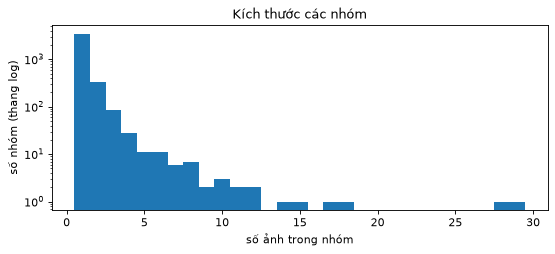

In [6]:
sizes = [len(m) for m in group_members.values()]
print("số nhóm theo số ảnh trong nhóm:", sorted(collections.Counter(sizes).items()))
multi = sum(s for s in sizes if s > 1)
print(f"{multi} ảnh ({multi / len(images):.1%}) có ít nhất một ảnh khác cùng nhóm")
print("8 nhóm lớn nhất:", [(class_of[m[0]], len(m)) for m in sorted(group_members.values(), key=len, reverse=True)[:8]])

plt.figure(figsize=(8, 3))
plt.hist(sizes, bins=np.arange(1, max(sizes) + 2) - 0.5, log=True)
plt.xlabel("số ảnh trong nhóm")
plt.ylabel("số nhóm (thang log)")
plt.title("Kích thước các nhóm")
plt.show()

Ví dụ nhóm lớn nhất của lớp TEA: nhiều loại trà khác nhau nhưng cùng một hãng, bao bì giống nhau nên bị nối thành một chuỗi. Nếu chia ngẫu nhiên, model sẽ thấy bao bì này ở train rồi gặp lại nó ở test.

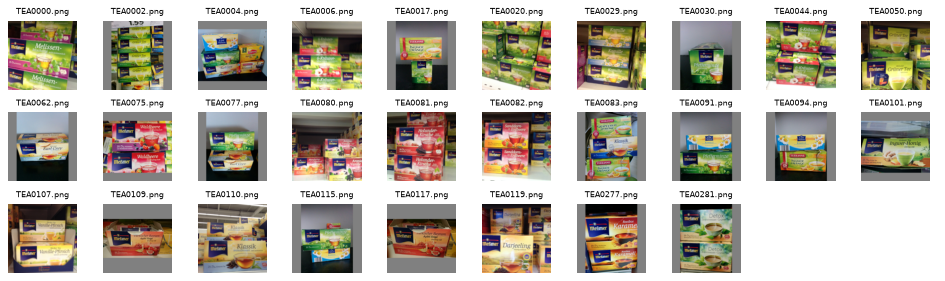

In [7]:
tea = max((m for m in group_members.values() if class_of[m[0]] == "TEA"), key=len)
show(tea, ncols=10, size=1.2)

## 4. Chia ngẫu nhiên thì sao?

`youonlycodeonce/splits_ngaunhien/` lưu cách chia ngẫu nhiên của bạn cùng nhóm: trong mỗi lớp, xáo ảnh rồi lấy 70% đầu làm train, 15% tiếp làm val, phần còn lại làm test. Ta đếm xem bao nhiêu ảnh test có ảnh cùng nhóm nằm trong train, và gọi những ảnh này là ảnh "rò rỉ". Với cách chia theo nhóm, con số này luôn bằng 0, vì chính các nhóm này được dùng để chia.

In [8]:
def read_split(folder):
    return {s: (SPLITS / folder / f"{s}.txt").read_text().split() for s in ["train", "val", "test"]}


def leaked(split):  # ảnh test có ít nhất một ảnh cùng nhóm nằm trong train
    train_groups = {group_of[im] for im in split["train"]}
    return [im for im in split["test"] if group_of[im] in train_groups]


nhom, ngaunhien = read_split("splits"), read_split("splits_ngaunhien")
for name, split in [("chia theo nhóm", nhom), ("chia ngẫu nhiên", ngaunhien)]:
    n = len(leaked(split))
    print(f"{name}: {n}/{len(split['test'])} ảnh test ({n / len(split['test']):.1%}) có ảnh cùng nhóm trong train")

where = {im: s for s, ims in ngaunhien.items() for im in ims}
cross = [d for d in duplicates if {where[im] for im in d} == {"train", "test"}]
print(len(cross), "cặp ảnh trùng từng pixel bị tách sang train và test:", cross)

chia theo nhóm: 0/751 ảnh test (0.0%) có ảnh cùng nhóm trong train
chia ngẫu nhiên: 212/756 ảnh test (28.0%) có ảnh cùng nhóm trong train
4 cặp ảnh trùng từng pixel bị tách sang train và test: [['COFFEE/COFFEE0092.png', 'COFFEE/COFFEE0193.png'], ['COFFEE/COFFEE0129.png', 'COFFEE/COFFEE0189.png'], ['SPICES/SPICES0001.png', 'SPICES/SPICES0181.png'], ['SPICES/SPICES0074.png', 'SPICES/SPICES0180.png']]


Vài ảnh test rò rỉ (bên trái) cạnh một ảnh cùng nhóm nằm trong train (bên phải). Model đã học ảnh bên phải, nên đoán đúng ảnh bên trái gần như chắc chắn:

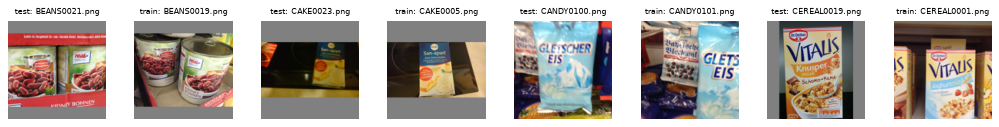

In [9]:
train_set = set(ngaunhien["train"])
pairs = []
for im in leaked(ngaunhien):
    if class_of[im] in {class_of[p[0]] for p in pairs}:
        continue  # mỗi lớp lấy một ví dụ
    pairs.append((im, next(t for t in group_members[group_of[im]] if t in train_set)))
    if len(pairs) == 4:
        break
names = [x for p in pairs for x in p]
show(names, ncols=8, titles=[("test: " if i % 2 == 0 else "train: ") + n.split("/")[1] for i, n in enumerate(names)])

Rò rỉ không phải do xui. Mô phỏng lại đúng cách chia của bạn cùng nhóm với 1.000 seed khác nhau, lần nào cũng có 21–30% ảnh test bị rò rỉ, trung bình khoảng 25%. Cách chia trong `splits_ngaunhien/` (28%, vạch đỏ) nằm ở phía cao:

1000 lần chia ngẫu nhiên: trung bình 25.2% ± 1.4, thấp nhất 20.9%, cao nhất 29.9%
chỉ 2.0% số lần chia rò rỉ nhiều hơn splits_ngaunhien/ (28.0%)


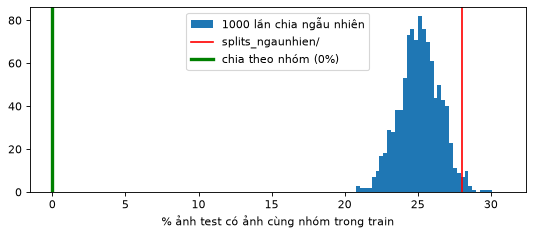

In [10]:
by_class = collections.defaultdict(list)
for im in images:
    by_class[class_of[im]].append(im)


def random_split(seed):  # như script của bạn cùng nhóm: xáo từng lớp, chia 70/15/15
    rnd, split = random.Random(seed), {"train": [], "val": [], "test": []}
    for c in classes:
        ims = by_class[c][:]
        rnd.shuffle(ims)
        n = len(ims)
        split["train"] += ims[:int(0.7 * n)]
        split["val"] += ims[int(0.7 * n):int(0.85 * n)]
        split["test"] += ims[int(0.85 * n):]
    return split


rates = np.array([100 * len(leaked(s)) / len(s["test"]) for s in map(random_split, range(1000))])
saved = 100 * len(leaked(ngaunhien)) / len(ngaunhien["test"])
print(f"1000 lần chia ngẫu nhiên: trung bình {rates.mean():.1f}% ± {rates.std():.1f}, "
      f"thấp nhất {rates.min():.1f}%, cao nhất {rates.max():.1f}%")
print(f"chỉ {np.mean(rates > saved):.1%} số lần chia rò rỉ nhiều hơn splits_ngaunhien/ ({saved:.1f}%)")

plt.figure(figsize=(8, 3))
# test luôn có 756 ảnh nên tỉ lệ chỉ nhận các giá trị k/756; mỗi cột gồm đúng 2 giá trị như vậy
plt.hist(rates, bins=np.arange(20, 31, 2 * 100 / 756), label="1000 lần chia ngẫu nhiên")
plt.axvline(saved, color="red", label="splits_ngaunhien/")
plt.axvline(0, color="green", linewidth=3, label="chia theo nhóm (0%)")
plt.xlabel("% ảnh test có ảnh cùng nhóm trong train")
plt.legend()
plt.show()

## 5. Rò rỉ làm accuracy cao hơn thực tế

Số liệu dưới đây lấy từ các lần train thật của 3 model (seed 42, xem bảng Kết quả trong README). File gốc là `checkpoints/logs_keras/leak_eval.json`, riêng dòng cuối lấy từ `leak_eval_goc.json` cùng thư mục; hai file này chỉ có trên máy đã train. Test của cách chia ngẫu nhiên được tách thành 212 ảnh rò rỉ và 544 ảnh còn lại:

| Model | Chia theo nhóm | Ngẫu nhiên: cả tập test | 212 ảnh rò rỉ | 544 ảnh còn lại |
|---|---|---|---|---|
| Model 1 (Simple CNN) | 84,6 | 86,1 | 98,1 | 81,4 |
| Model 2 (Deep CNN) | 88,9 | 91,7 | 99,1 | 88,8 |
| Model 3 (ResNet50) | 91,3 | 93,0 | 98,1 | 91,0 |
| Model 3, công thức ban đầu | 83,6 | 88,1 | 96,2 | 84,9 |

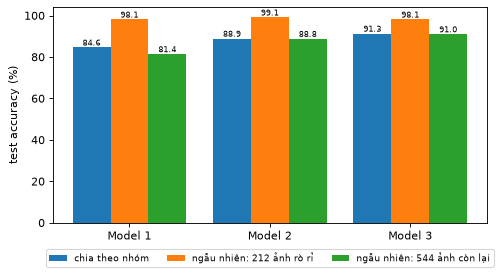

Model 1: ảnh rò rỉ cộng thêm 4.7 điểm so với 544 ảnh còn lại
Model 2: ảnh rò rỉ cộng thêm 2.9 điểm so với 544 ảnh còn lại
Model 3: ảnh rò rỉ cộng thêm 2.0 điểm so với 544 ảnh còn lại


In [11]:
# số liệu ở bảng trên (3 model chính)
models = ["Model 1", "Model 2", "Model 3"]
results = {"chia theo nhóm": [84.6, 88.9, 91.3],
           "ngẫu nhiên: 212 ảnh rò rỉ": [98.1, 99.1, 98.1],
           "ngẫu nhiên: 544 ảnh còn lại": [81.4, 88.8, 91.0]}
x = np.arange(len(models))
plt.figure(figsize=(7, 3.5))
for i, (name, values) in enumerate(results.items()):
    bars = plt.bar(x + 0.27 * (i - 1), values, width=0.27, label=name)
    plt.bar_label(bars, fmt="%.1f", fontsize=7)
plt.xticks(x, models)
plt.ylabel("test accuracy (%)")
plt.legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.show()

full_random = [86.1, 91.7, 93.0]  # cả tập test của cách chia ngẫu nhiên
for m, full, clean in zip(models, full_random, results["ngẫu nhiên: 544 ảnh còn lại"]):
    print(f"{m}: ảnh rò rỉ cộng thêm {full - clean:.1f} điểm so với 544 ảnh còn lại")

- Với ảnh rò rỉ, 3 model đều đúng 98–99% (công thức ban đầu của Model 3: 96%), vì đã gặp gần như đúng ảnh đó lúc train.
- Với 544 ảnh còn lại, accuracy của 3 model ngang hoặc thấp hơn cách chia theo nhóm. Riêng công thức ban đầu của Model 3 thì cao hơn một chút (84,9 so với 83,6).
- Cách chia ngẫu nhiên vì vậy cho điểm cao hơn 1,6–2,7 điểm. Phần ảnh rò rỉ không giúp phân biệt model nào tốt hơn, vì model nào cũng đoán đúng gần hết, mà chỉ cộng thêm điểm. Điểm cộng lại không đều: model yếu được cộng nhiều hơn (Model 1 +4,7, Model 2 +2,9, Model 3 +2,0 so với 544 ảnh còn lại). Khoảng cách giữa các model vì vậy bị thu hẹp, và so sánh trên cách chia ngẫu nhiên kém tin cậy hơn.
- Bài báo gốc của bộ dữ liệu (Jund và cs., 2016; CaffeNet đạt 78,9%) chia ảnh thành 5 phần ngẫu nhiên theo từng ảnh, không gom nhóm, nên con số đó nhiều khả năng cũng cao hơn thực tế.

## 6. Cách chia theo nhóm có cân bằng không?

Mỗi nhóm nằm trọn trong một tập, và tỉ lệ train/val/test của từng lớp vẫn giữ quanh 70/15/15:

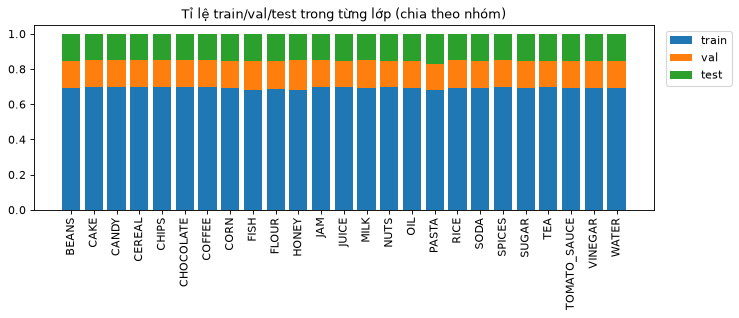

tỉ lệ train của các lớp: 0.68 – 0.70


In [12]:
where_nhom = {im: s for s, ims in nhom.items() for im in ims}
assert all(len({where_nhom[im] for im in m}) == 1 for m in group_members.values())  # mỗi nhóm nằm trọn trong một tập
frac = {s: np.array([sum(split_of[im] == s for im in by_class[c]) / len(by_class[c]) for c in classes])
        for s in ["train", "val", "test"]}
bottom = np.zeros(len(classes))
plt.figure(figsize=(10, 3))
for s in ["train", "val", "test"]:
    plt.bar(classes, frac[s], bottom=bottom, label=s)
    bottom += frac[s]
plt.xticks(rotation=90)
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.title("Tỉ lệ train/val/test trong từng lớp (chia theo nhóm)")
plt.show()
print(f"tỉ lệ train của các lớp: {frac['train'].min():.2f} – {frac['train'].max():.2f}")

Cái giá phải trả: ở vài lớp, một nhóm lớn chiếm từ gần một nửa đến khoảng 2/3 số ảnh val hoặc test của lớp đó. Accuracy của riêng các lớp này vì vậy dao động nhiều hơn, vì đoán sai một nhóm là mất cả mảng.

In [13]:
for s in ["val", "test"]:
    worst = []
    for c in classes:
        groups = collections.Counter(group_of[im] for im in nhom[s] if class_of[im] == c)
        top, total = groups.most_common(1)[0][1], sum(groups.values())
        worst.append((top / total, c, top, total))
    print(s + ":", ", ".join(f"{c} {top}/{total} ảnh cùng một nhóm" for _, c, top, total in sorted(worst, reverse=True)[:4]))

val: TEA 28/43 ảnh cùng một nhóm, HONEY 18/32 ảnh cùng một nhóm, CAKE 14/25 ảnh cùng một nhóm, CORN 7/15 ảnh cùng một nhóm
test: RICE 11/22 ảnh cùng một nhóm, SUGAR 6/18 ảnh cùng một nhóm, CEREAL 12/42 ảnh cùng một nhóm, FISH 4/17 ảnh cùng một nhóm


Cách gom nhóm dựa vào ngưỡng số điểm khớp, nên vẫn có thể sót vài cặp gần giống. Ví dụ dưới đây gần như cùng một ảnh nhưng chỉ khớp 9 điểm, dưới ngưỡng 10, nên nằm ở hai nhóm khác nhau, một ảnh ở test và một ảnh ở train:

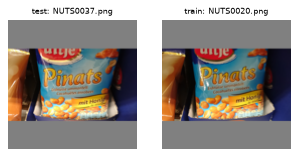

In [14]:
pair = ["NUTS/NUTS0037.png", "NUTS/NUTS0020.png"]
show(pair, ncols=2, size=2, titles=[f"{split_of[im]}: {im.split('/')[1]}" for im in pair])

## 7. Kết luận

- Khoảng 30% số ảnh có ít nhất một ảnh khác cùng nhóm (chụp lại cùng kệ hoặc cùng mẫu bao bì), kể cả 14 cặp trùng nhau từng pixel.
- Chia ngẫu nhiên theo từng ảnh thì khoảng 25% ảnh test (28% với `splits_ngaunhien/`) có ảnh cùng nhóm nằm trong train. Model đoán đúng 98–99% số ảnh này, nên test accuracy cao hơn khả năng thật của model với ảnh mới.
- Ảnh rò rỉ cộng điểm cho mọi model nhưng không đều (model yếu được cộng nhiều hơn), nên so sánh model trên cách chia ngẫu nhiên kém tin cậy hơn.
- Chia theo nhóm đưa trọn mỗi nhóm vào một tập và vẫn giữ tỉ lệ 70/15/15 trong từng lớp. Rò rỉ giảm đi rất nhiều, dù không hẳn bằng 0 vì bước gom nhóm có thể sót vài cặp. Test lúc này đo sát hơn điều ta cần: model làm tốt đến đâu với những cảnh chụp nó chưa thấy.
- Đổi lại, val/test của vài lớp có nhiều ảnh từ cùng một nhóm, nên accuracy theo từng lớp dao động hơn. Vì vậy nên nhìn accuracy chung của cả tập, và so sánh các model trên cùng một test set.